# Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

#====
from sklearn.impute import SimpleImputer
#====
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


# load Data

In [2]:
df=pd.read_csv('train.csv')
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


# visulization


In [3]:
def plot_all_columns(df):
    cat_cols = df.select_dtypes(include=['object', 'category']).columns
    num_cols = df.drop("Id",axis=1).select_dtypes(include='number').columns
    # Numerical Columns
    for col in num_cols:
        plt.figure(figsize=(8, 4))
        sns.histplot(data=df, x=col, kde=True)
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()
    # Categorical Columns
    for col in cat_cols:
        plt.figure(figsize=(8, 4))
        top_values = df[col].value_counts().head(10).index
        sns.countplot(
            data=df[df[col].isin(top_values)],
            x=col,
            order=top_values
        )
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

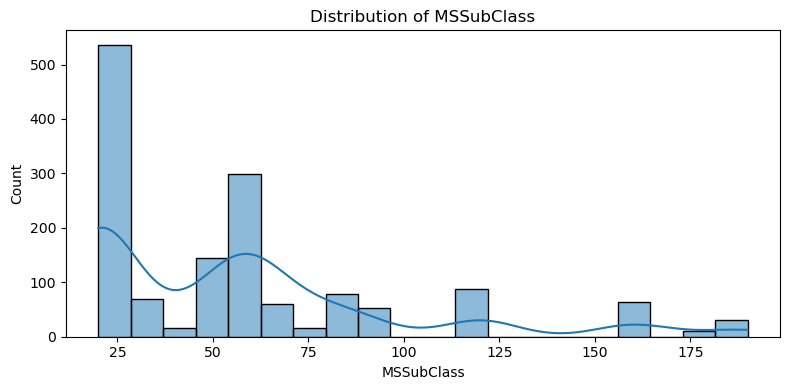

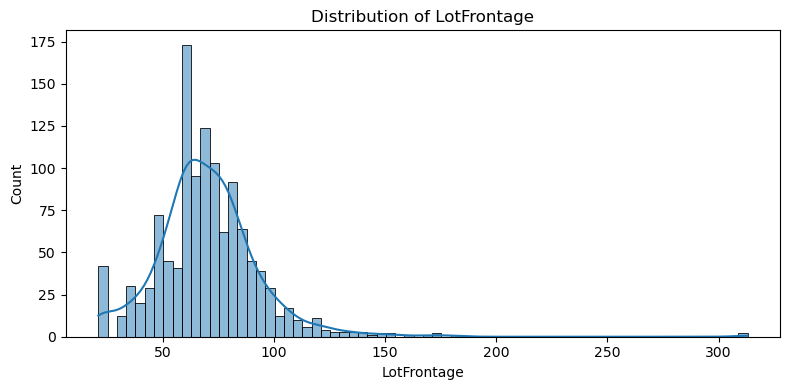

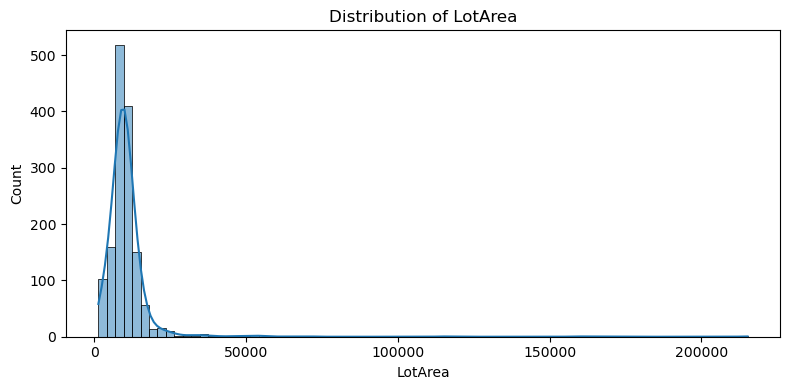

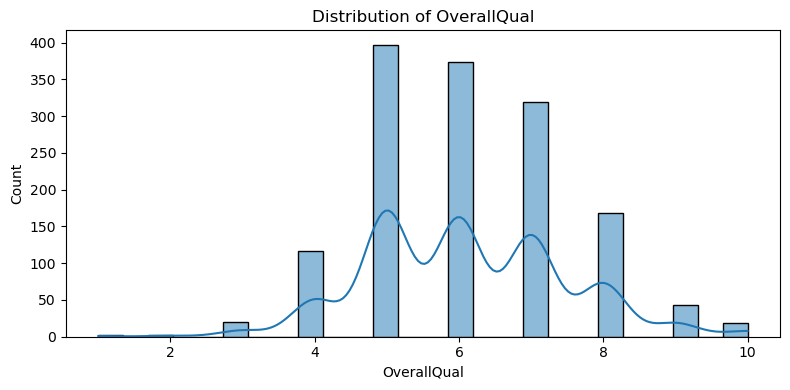

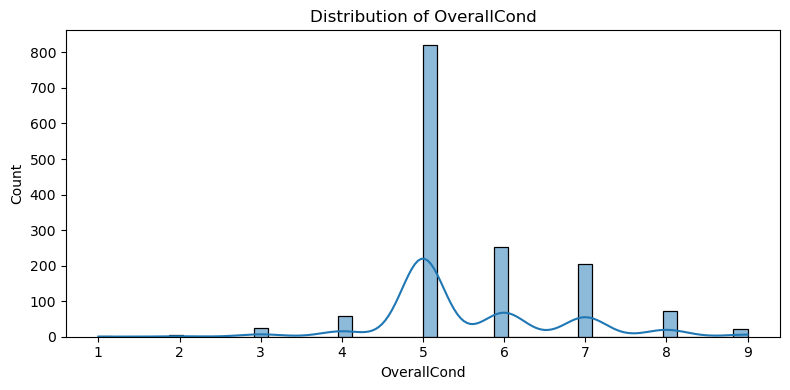

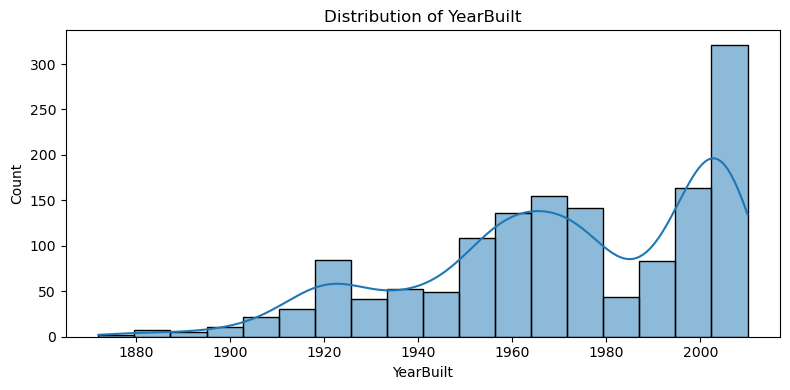

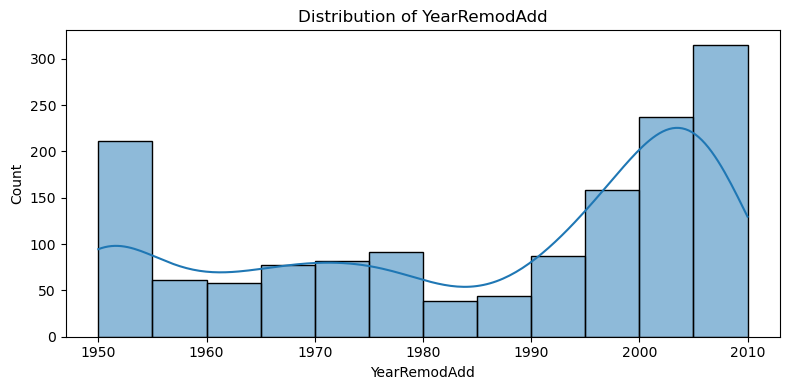

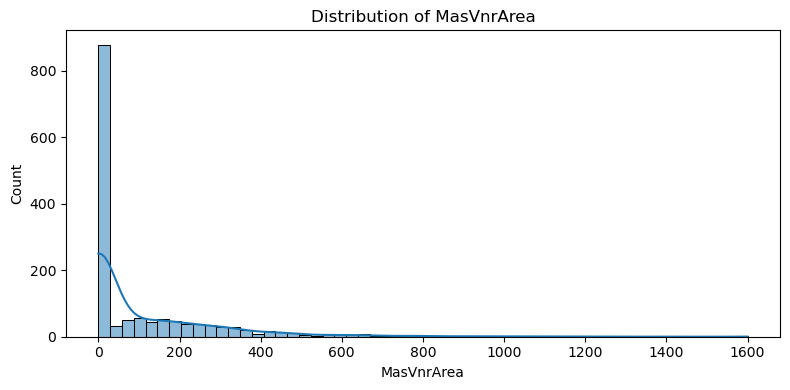

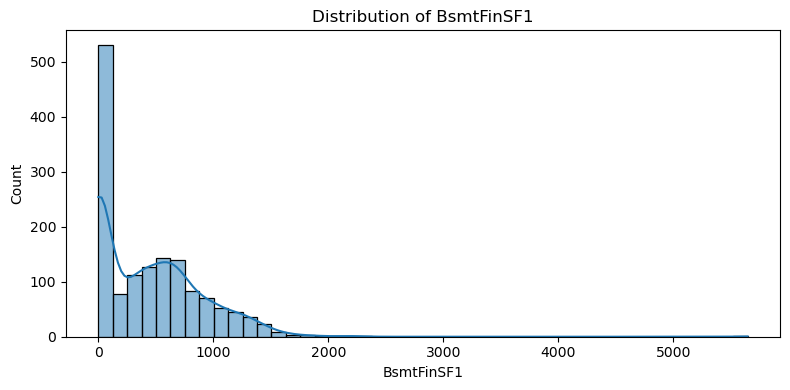

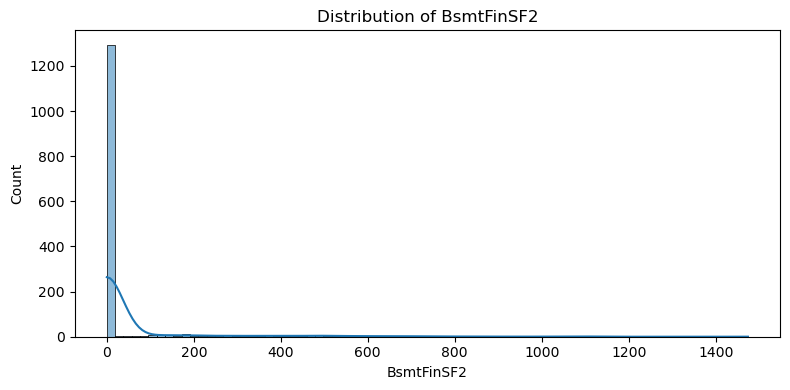

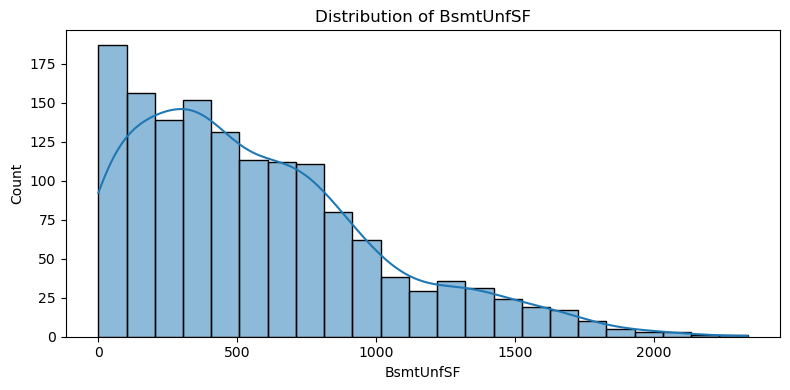

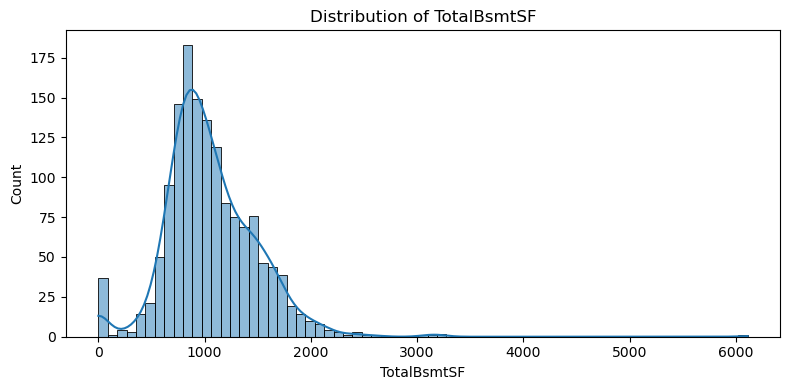

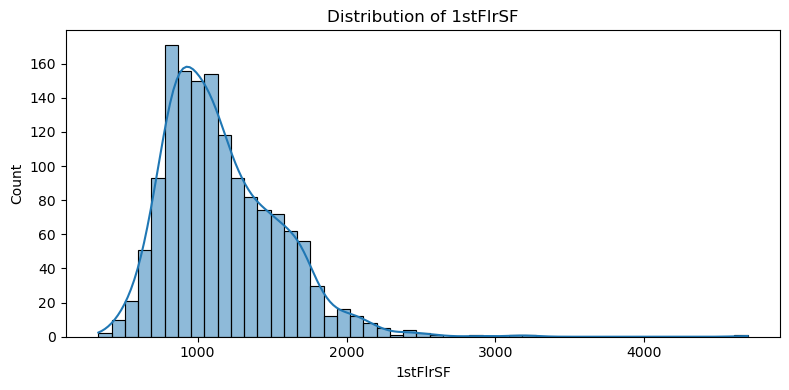

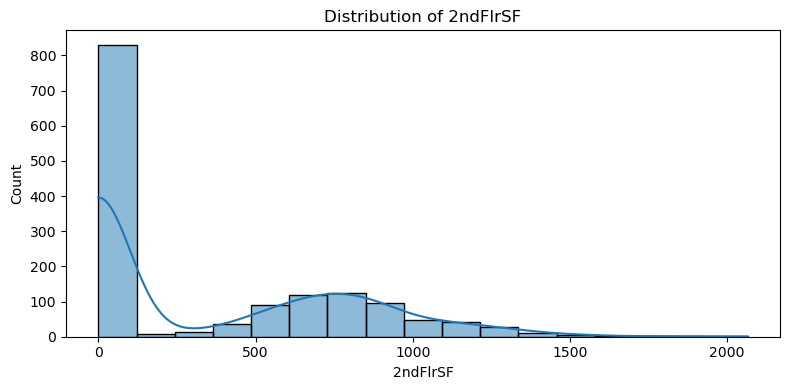

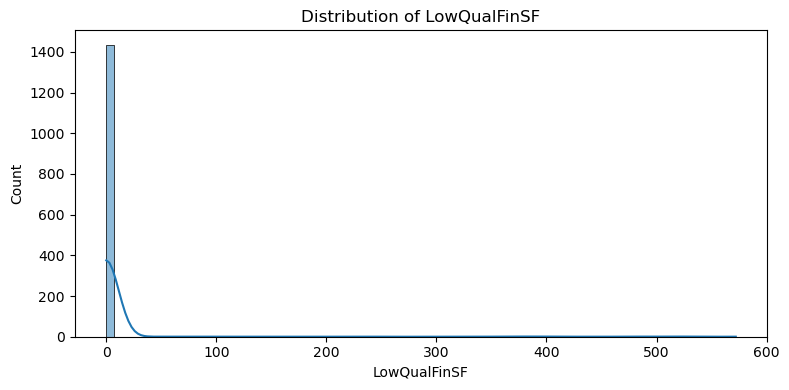

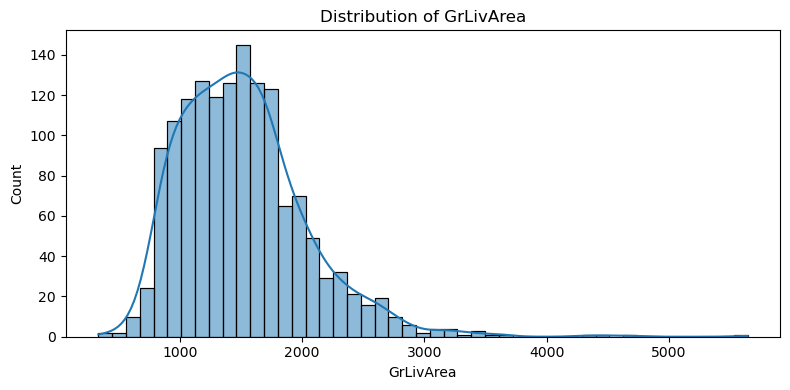

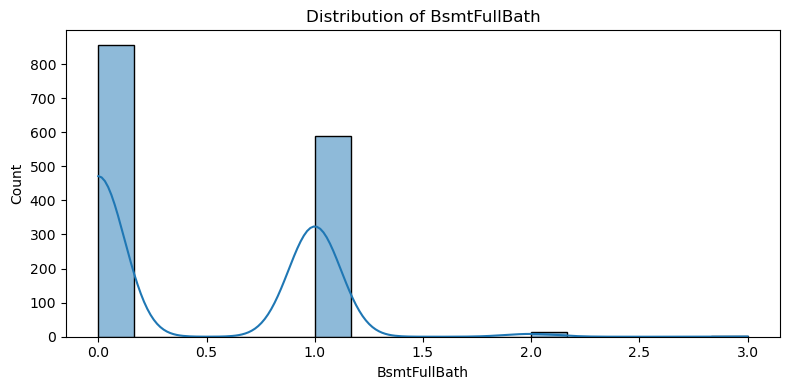

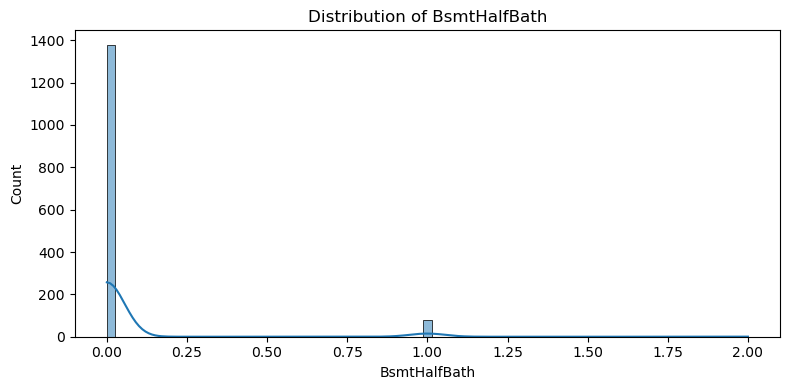

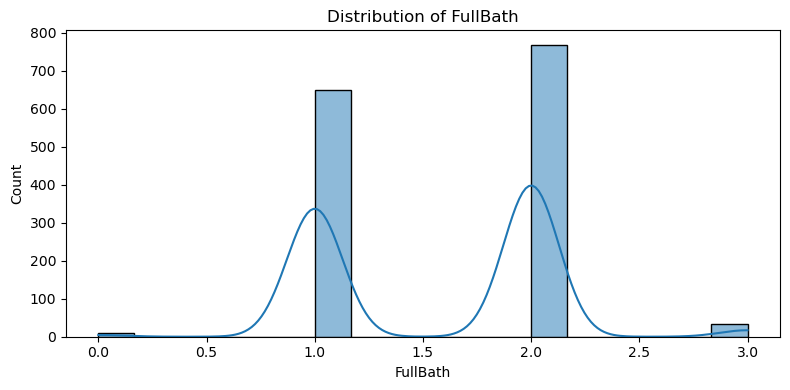

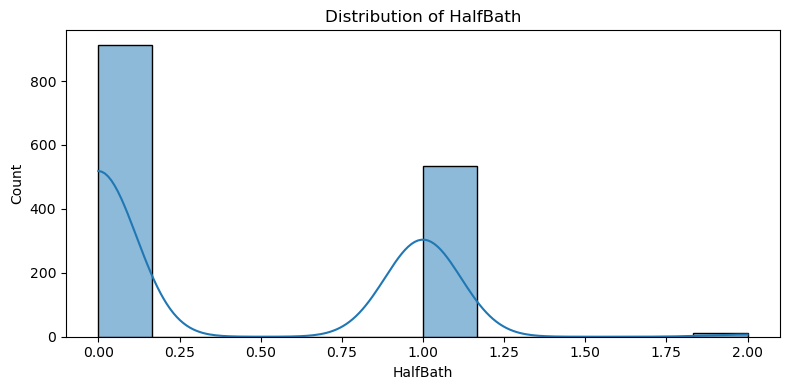

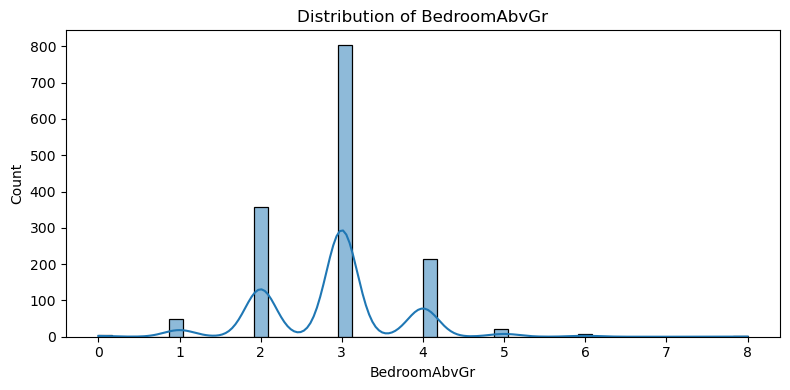

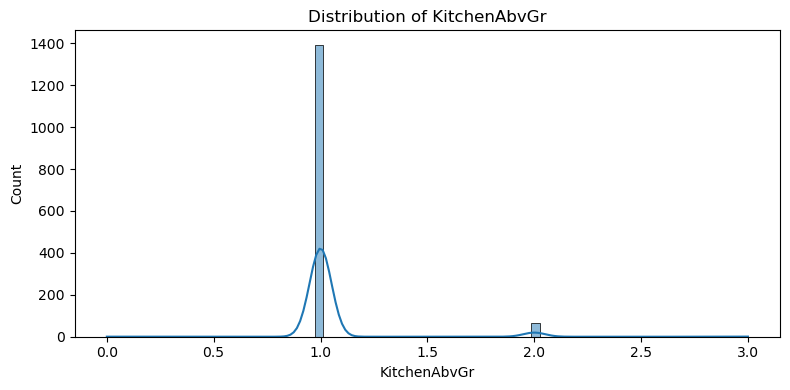

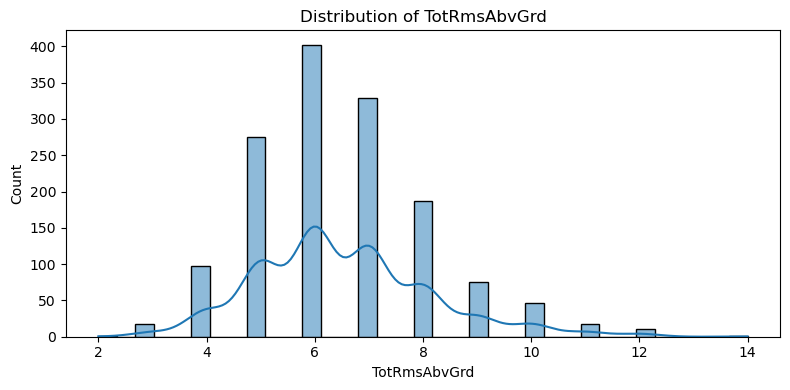

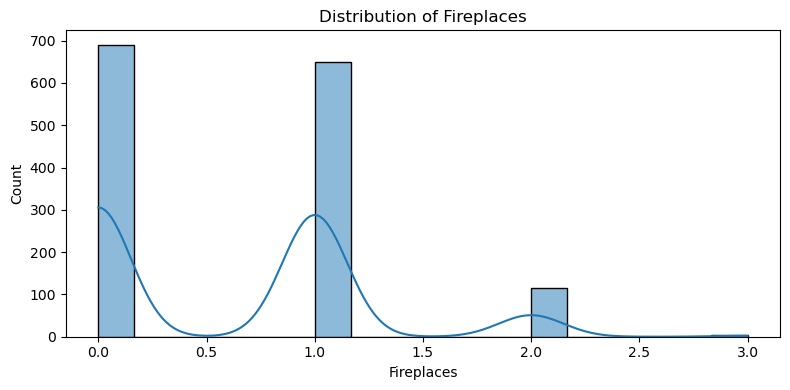

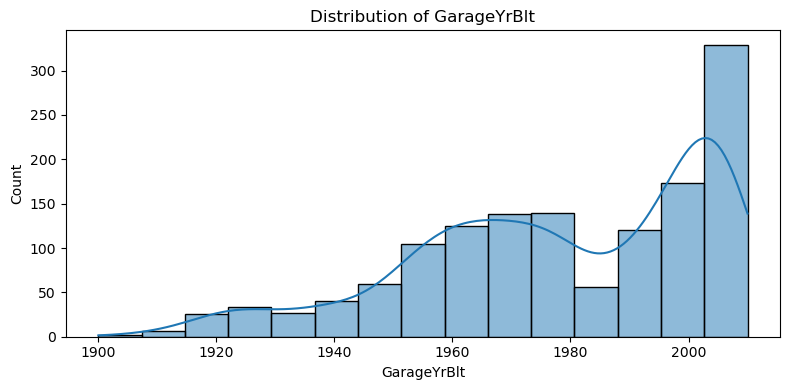

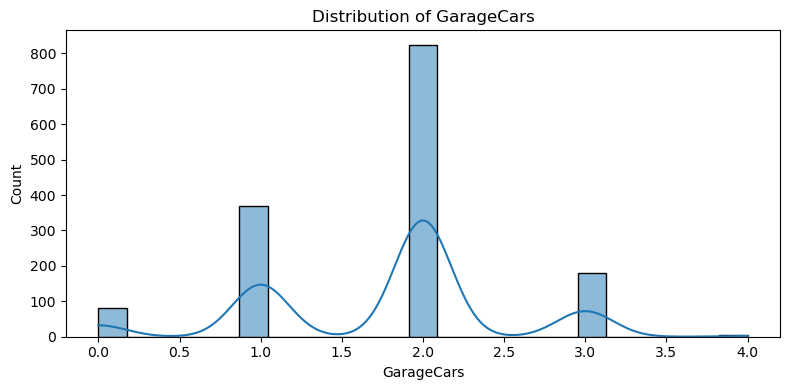

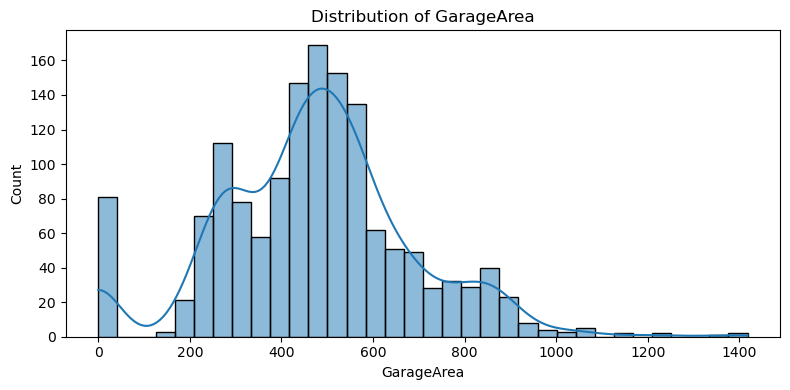

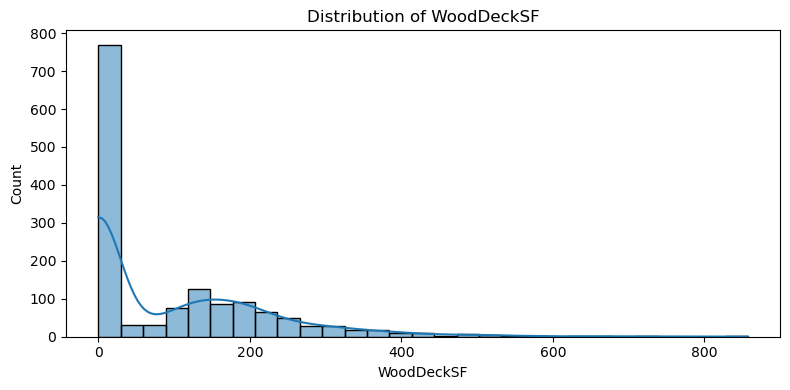

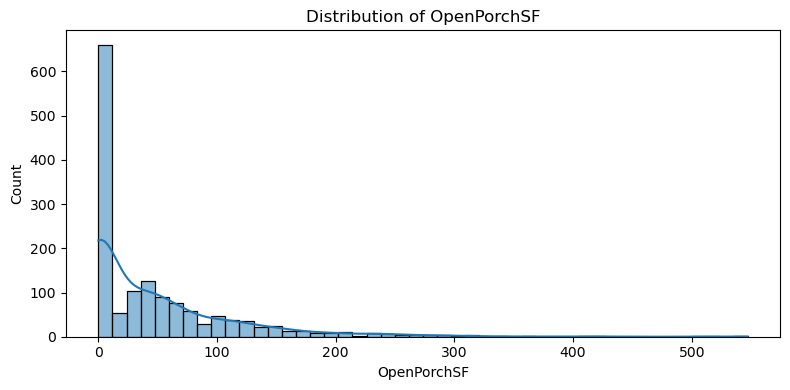

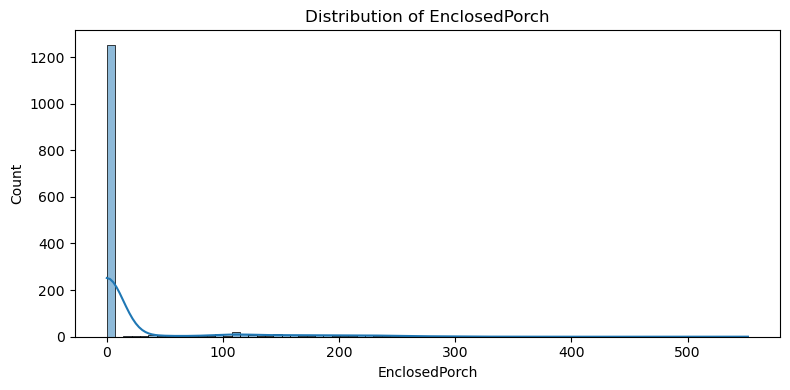

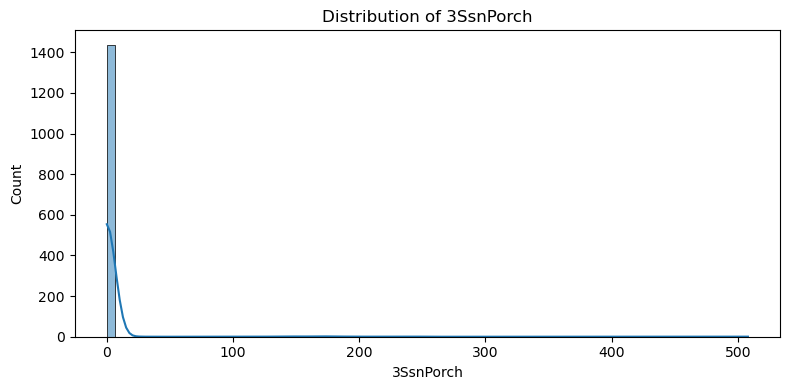

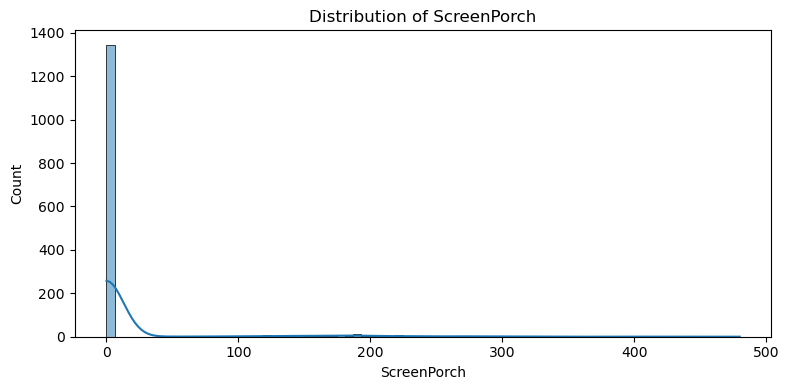

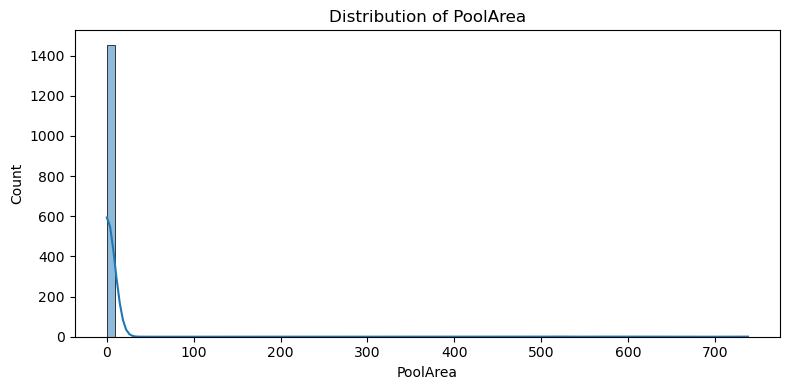

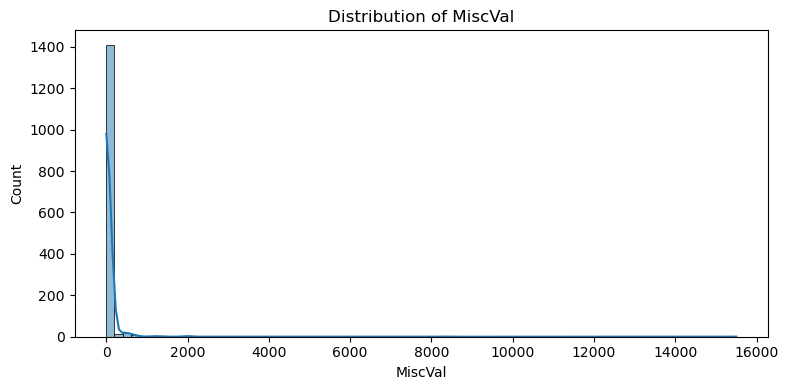

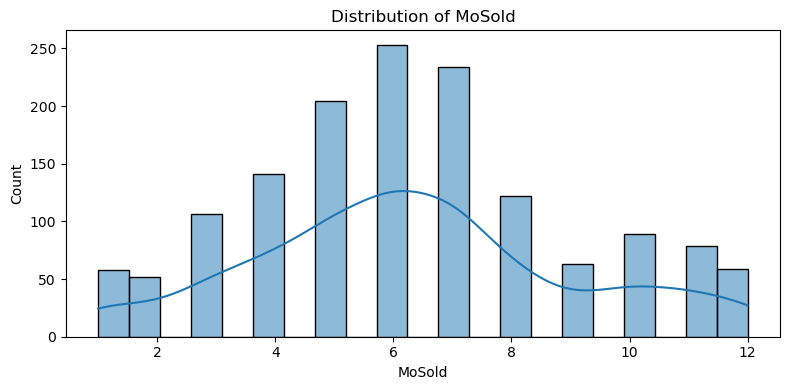

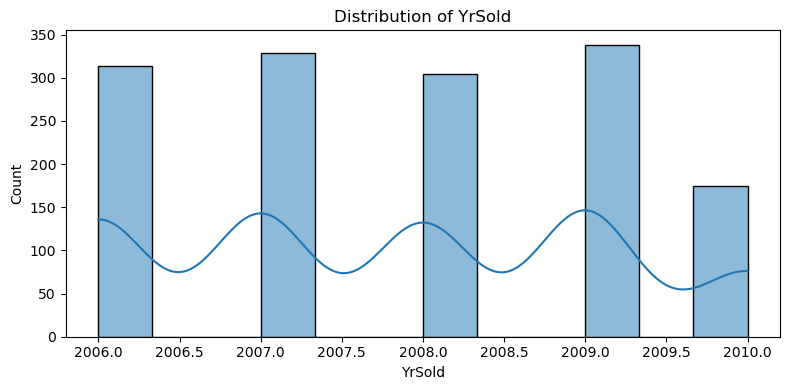

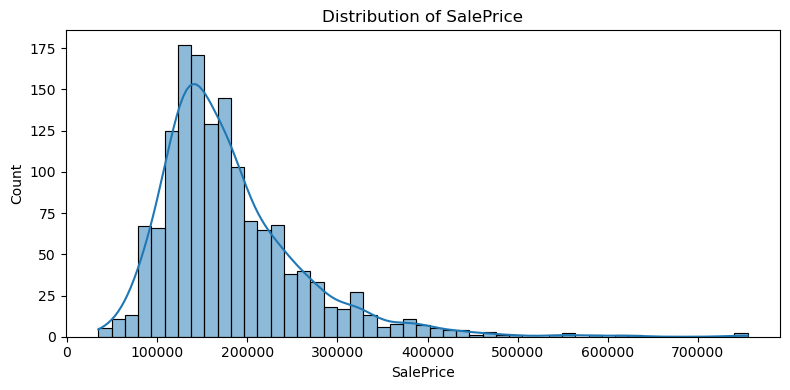

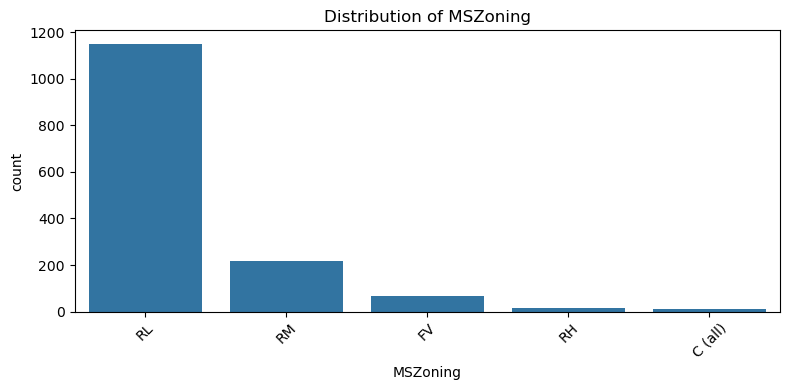

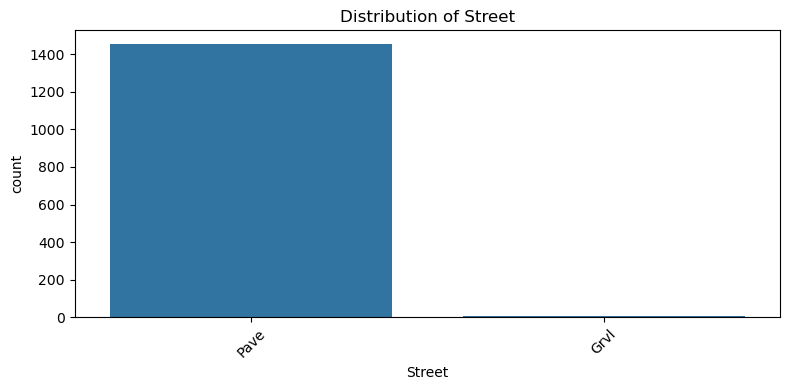

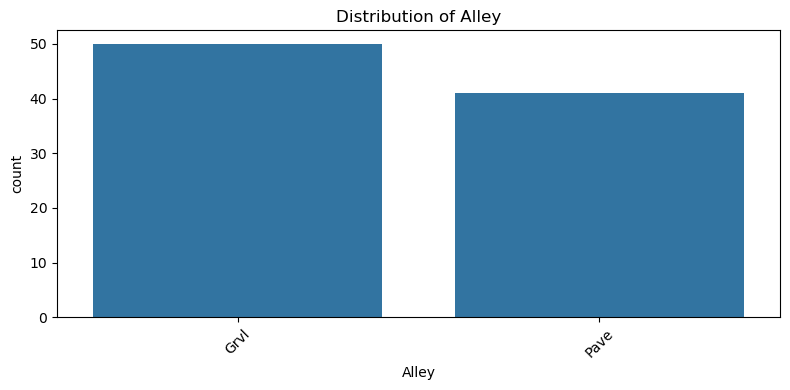

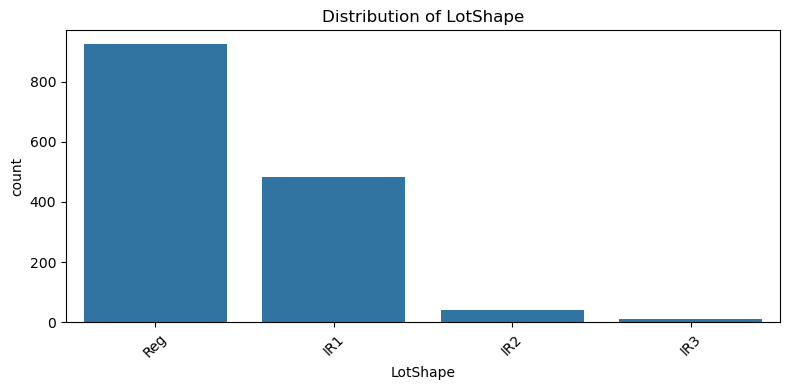

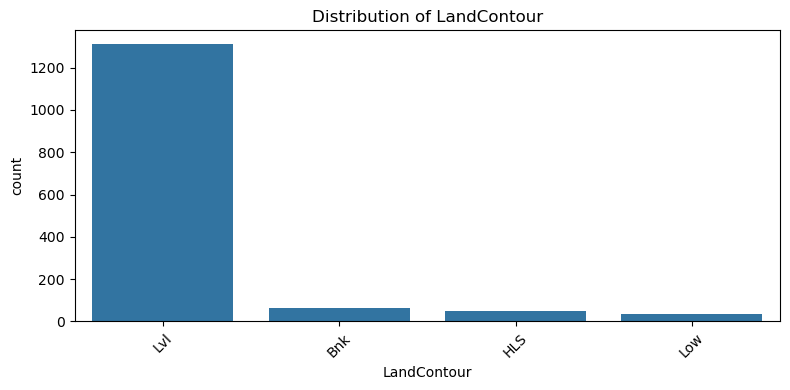

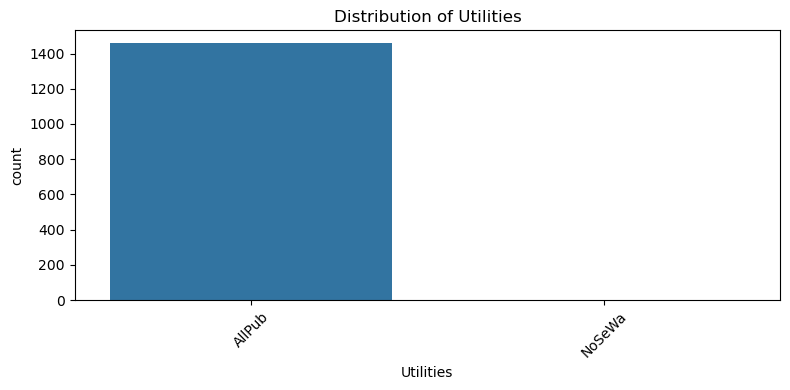

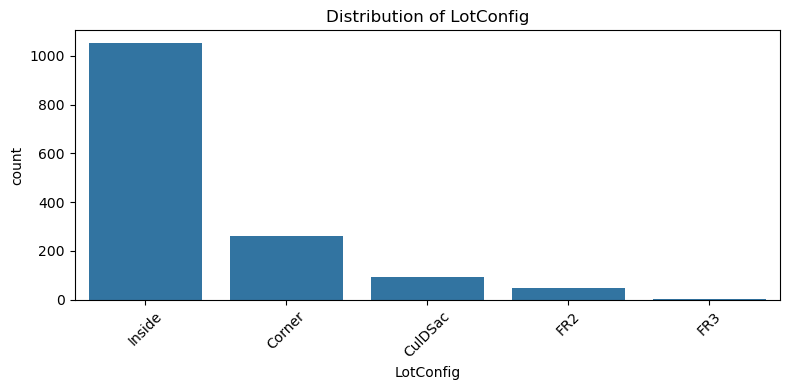

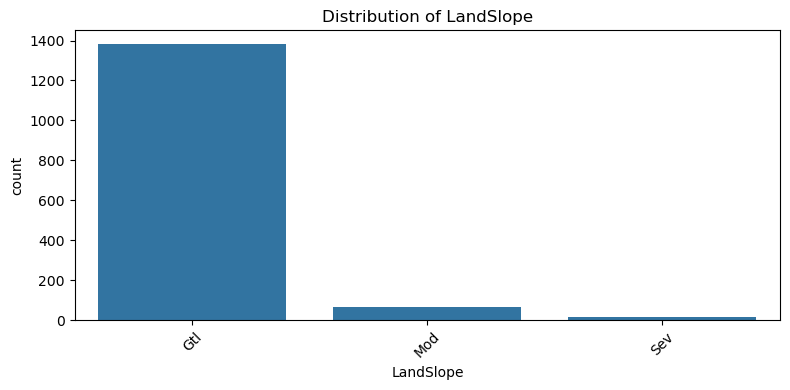

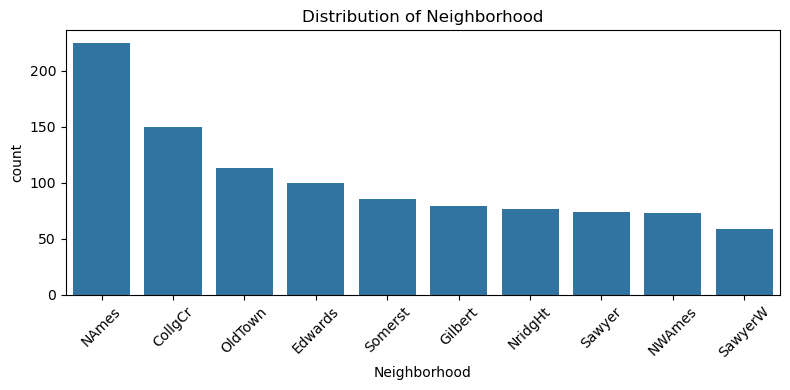

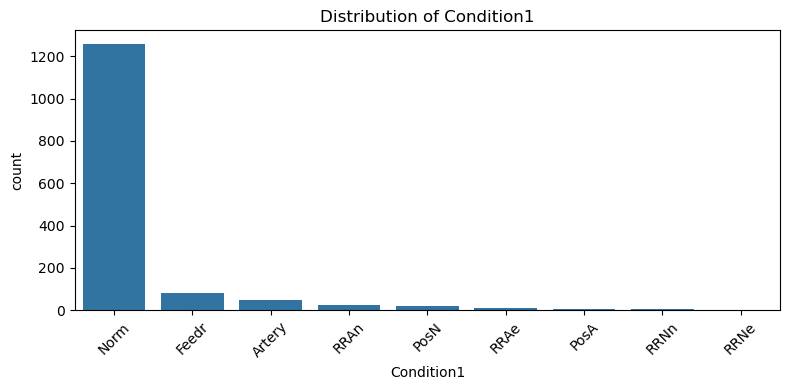

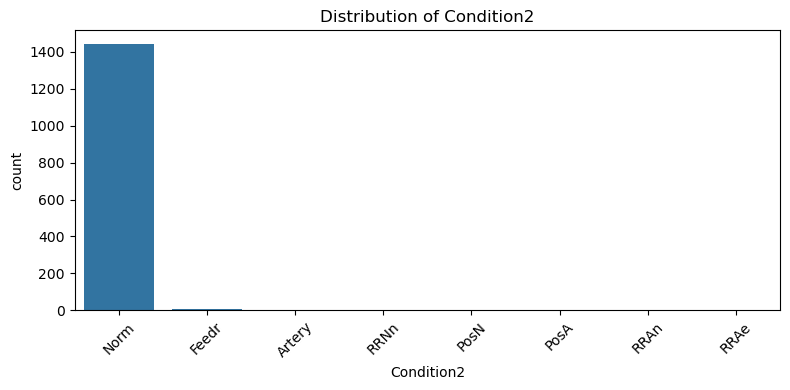

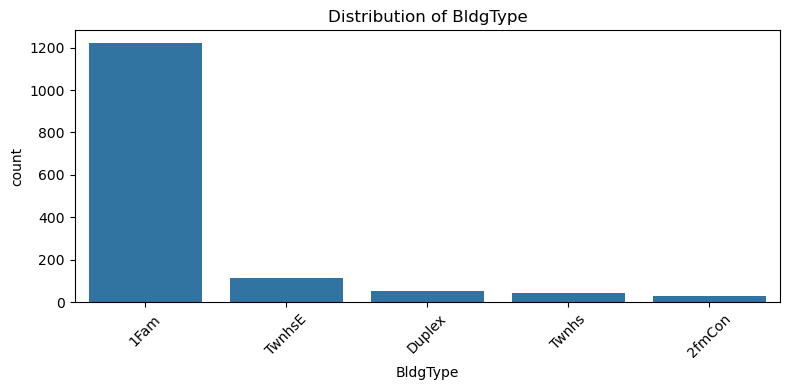

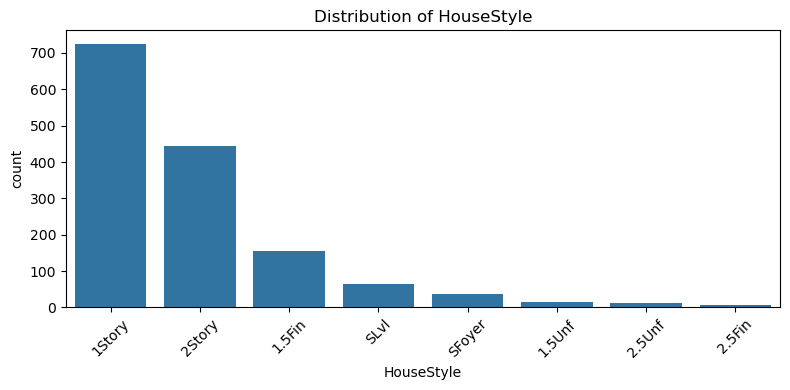

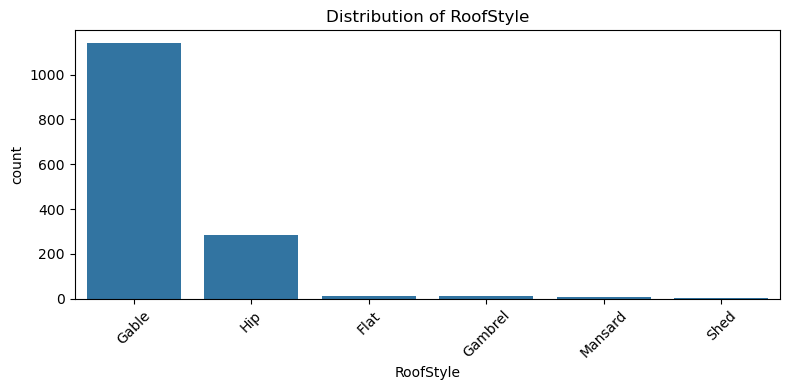

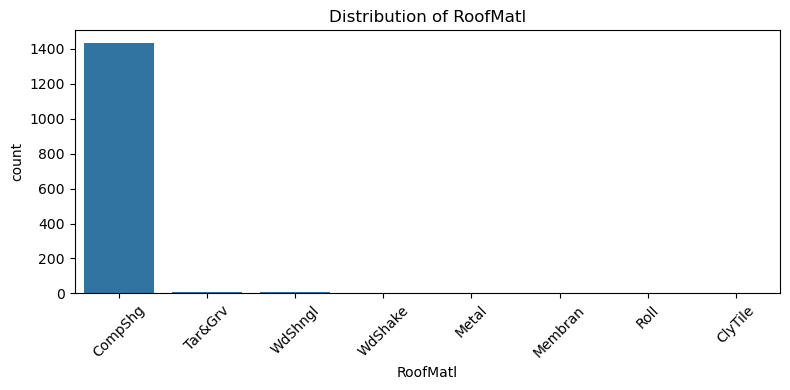

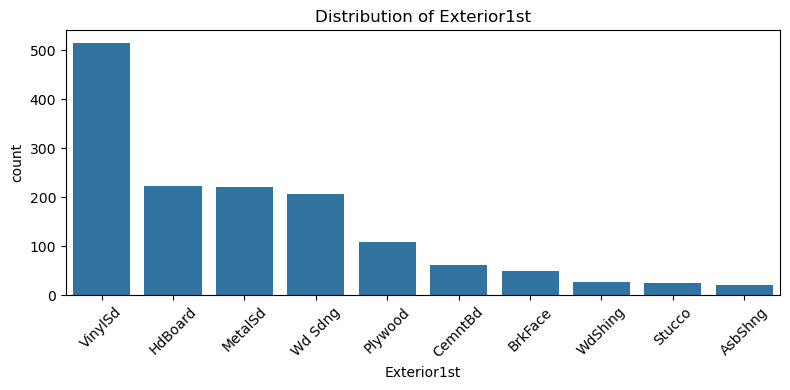

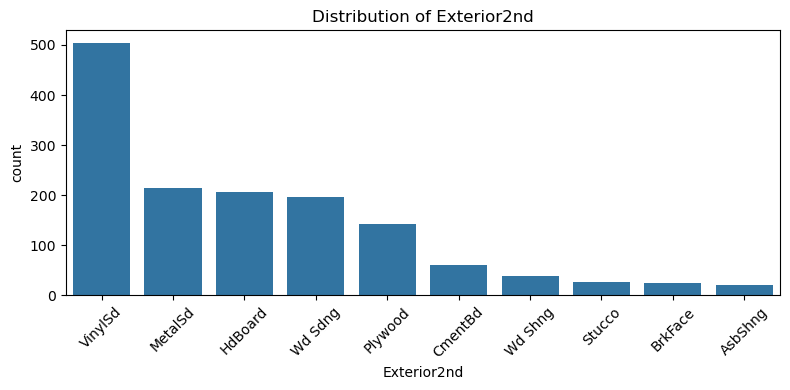

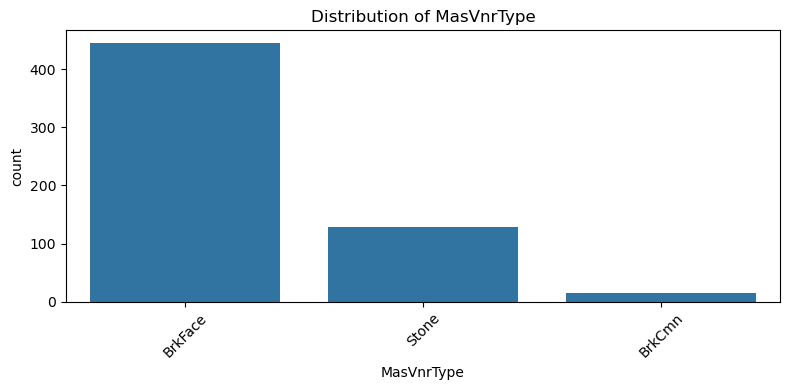

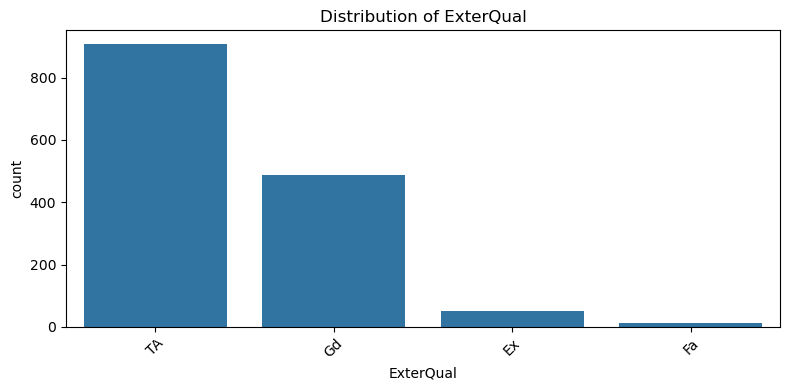

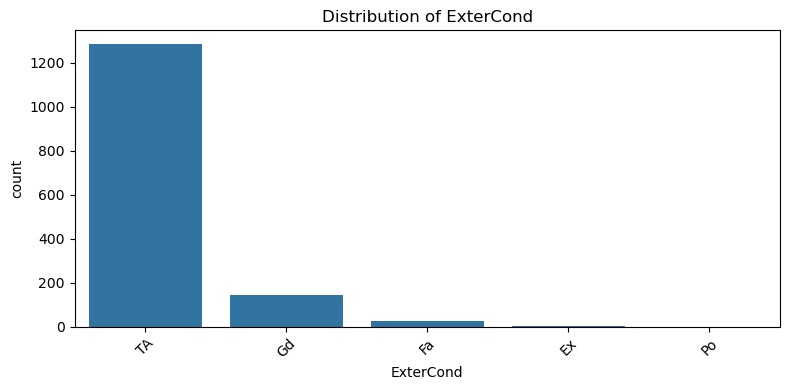

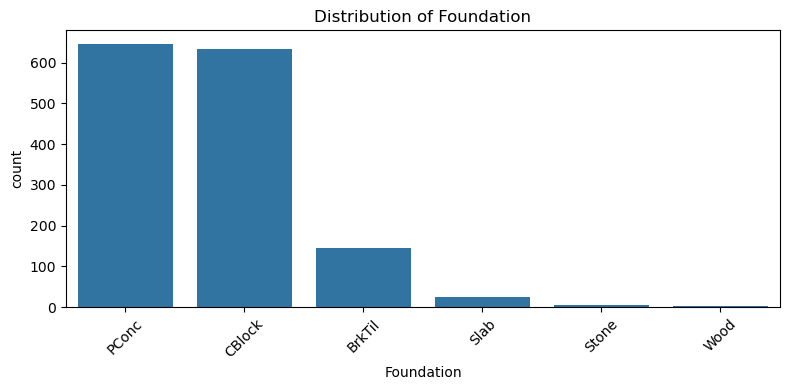

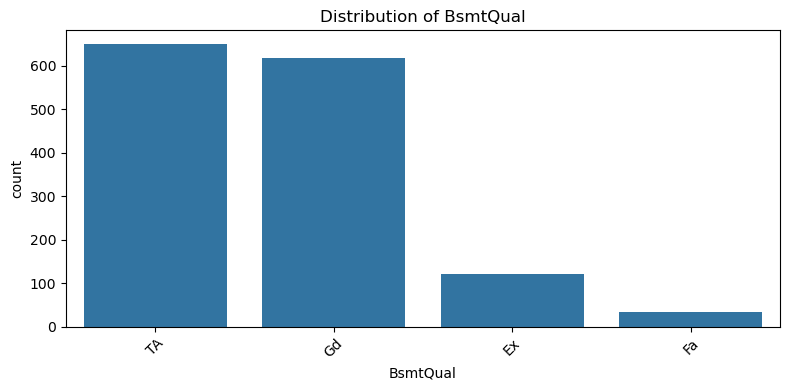

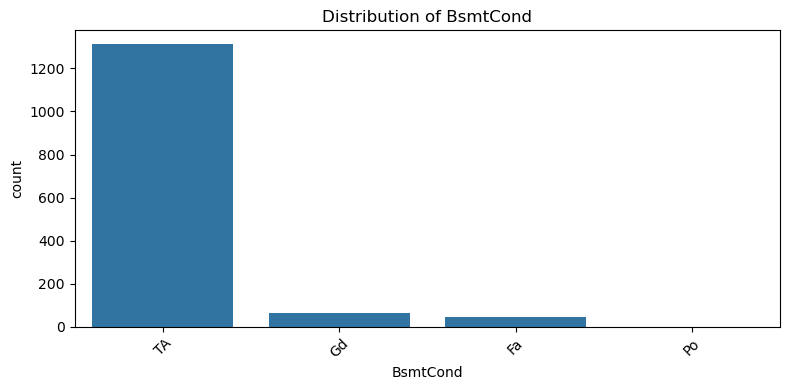

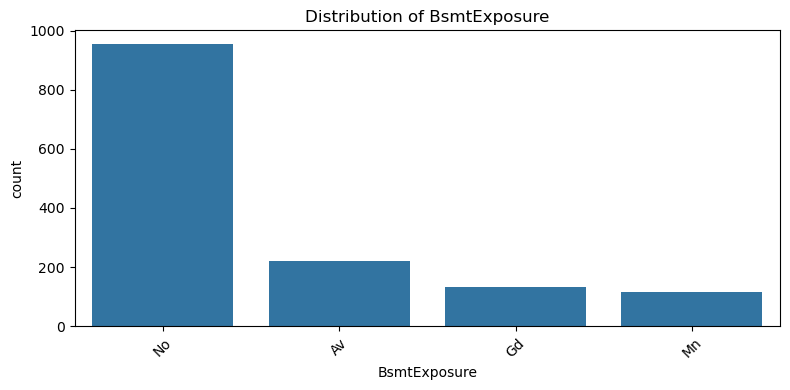

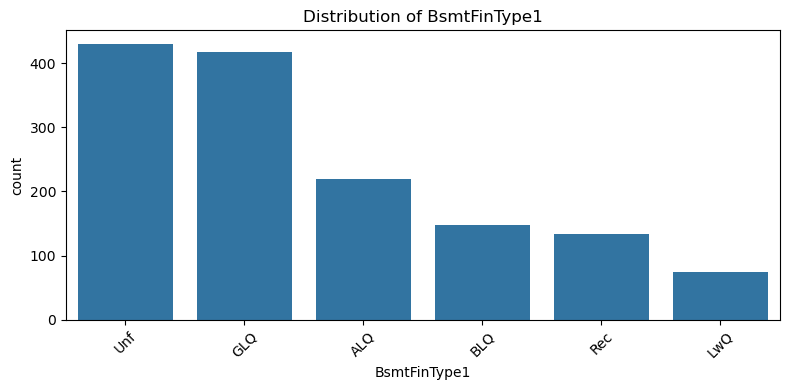

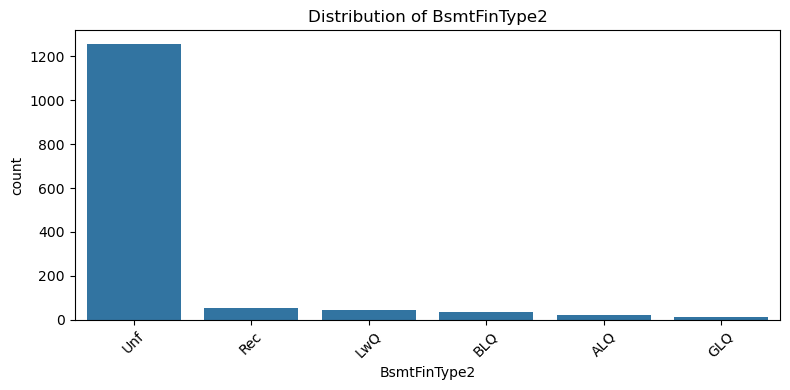

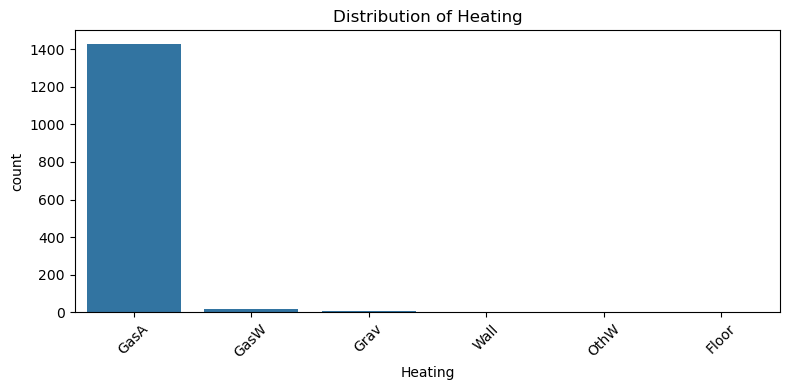

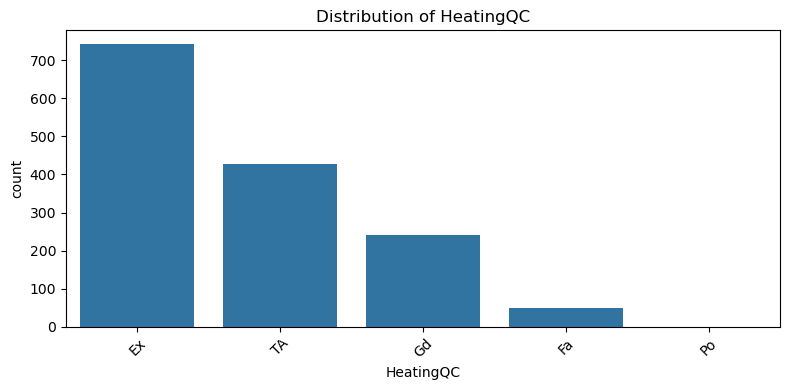

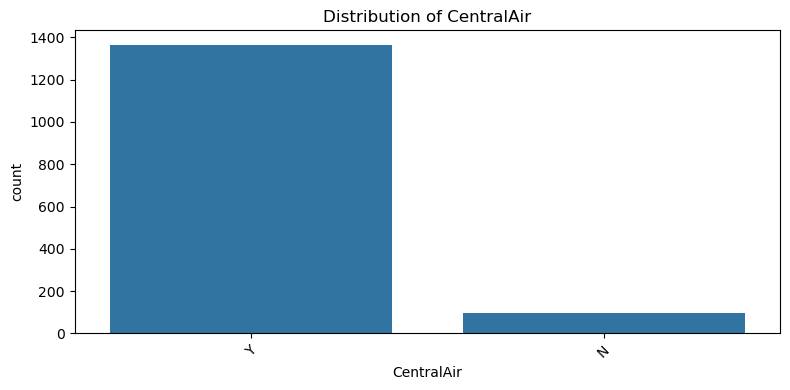

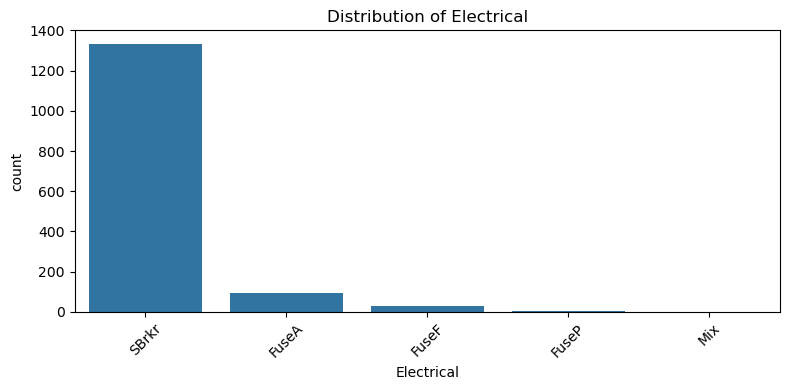

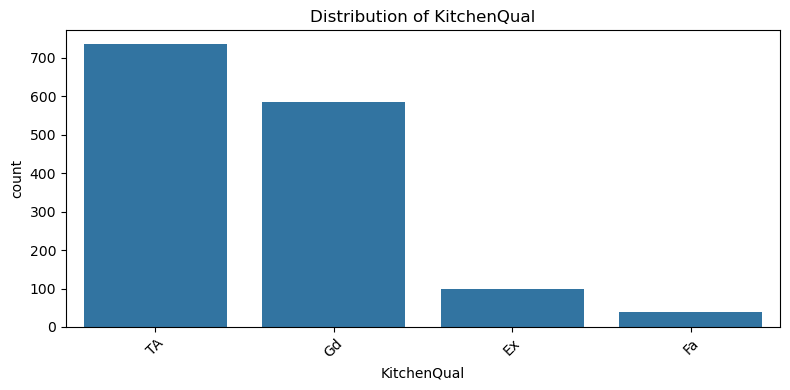

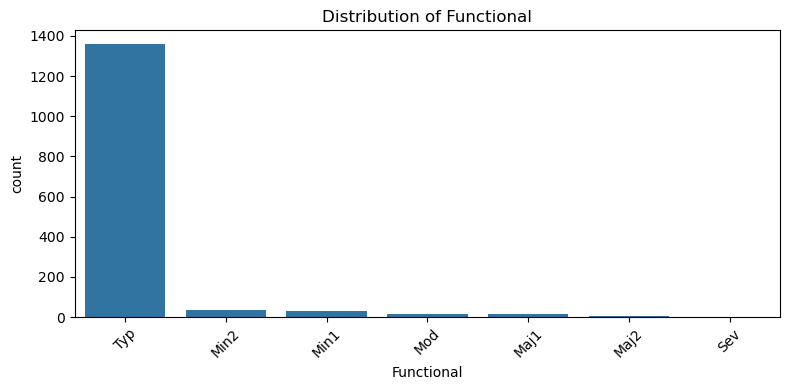

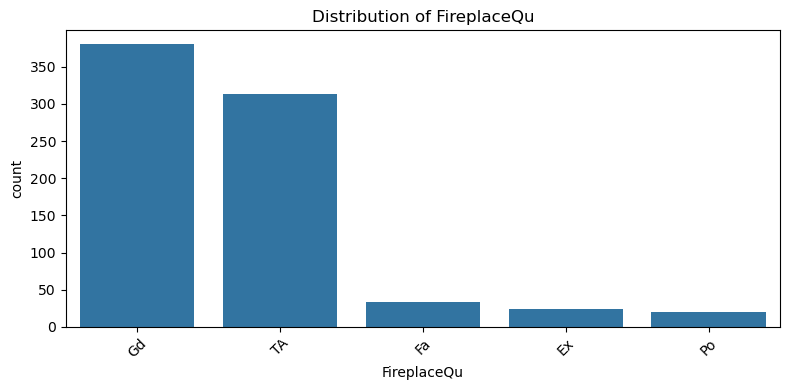

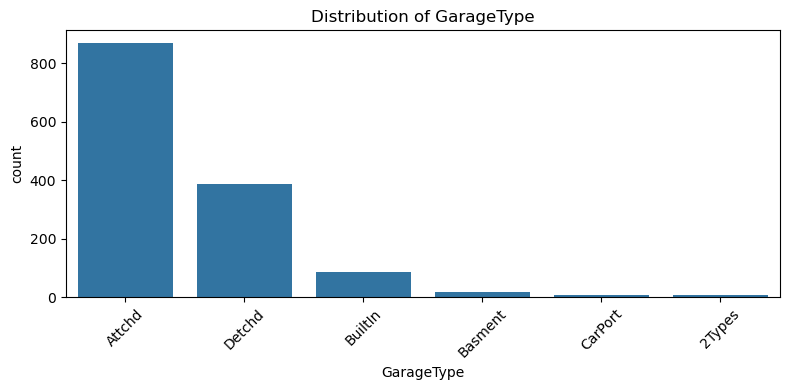

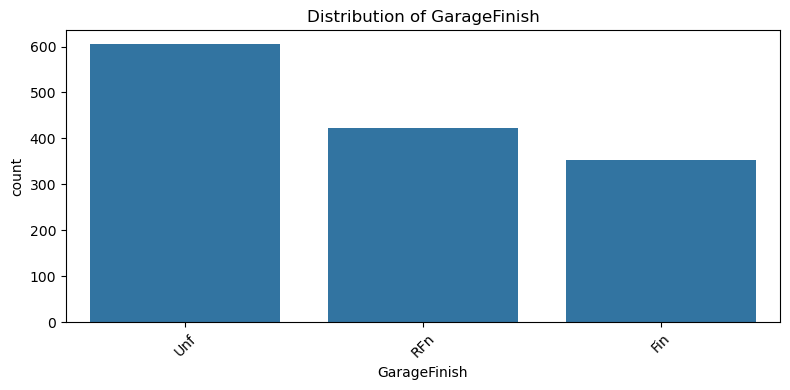

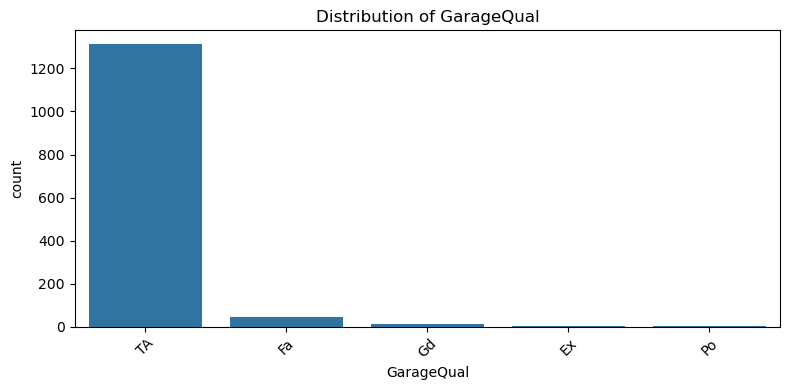

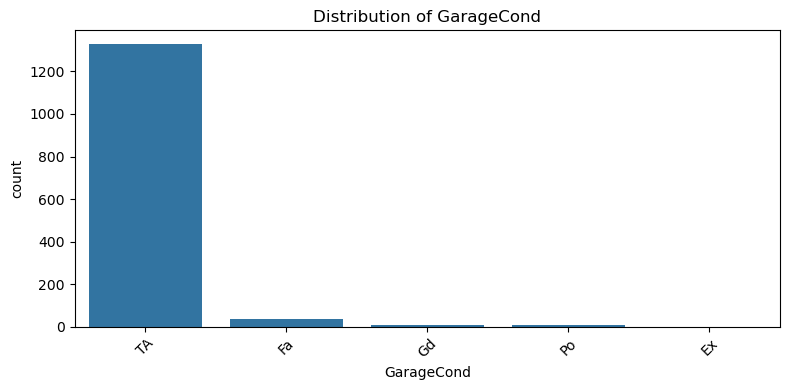

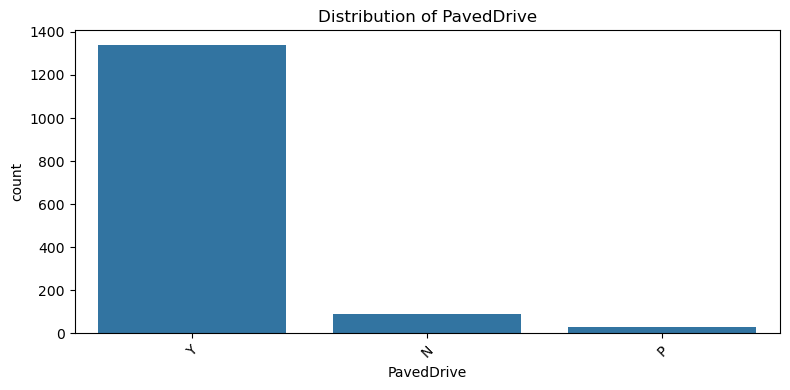

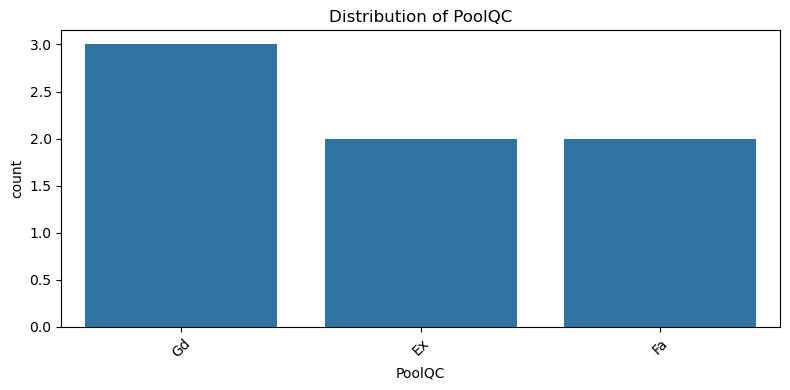

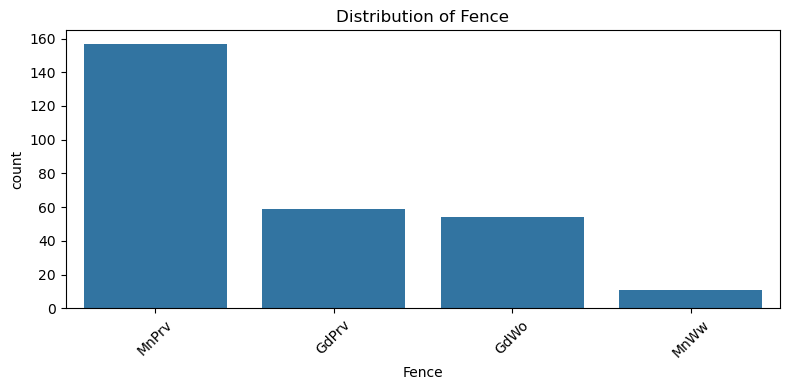

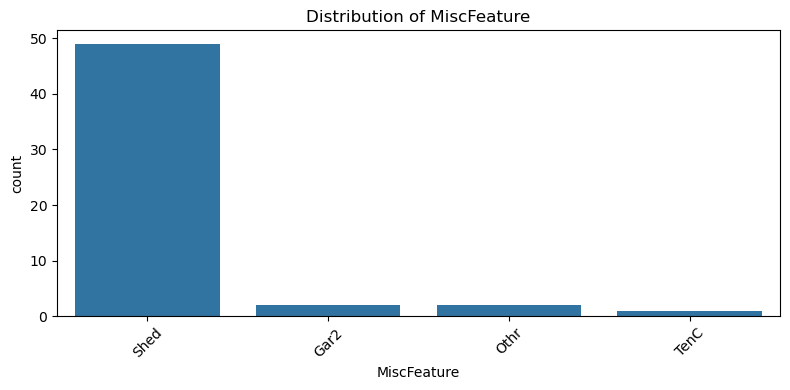

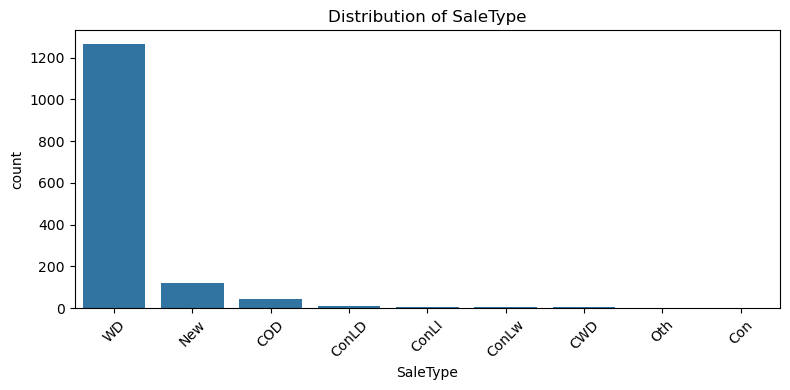

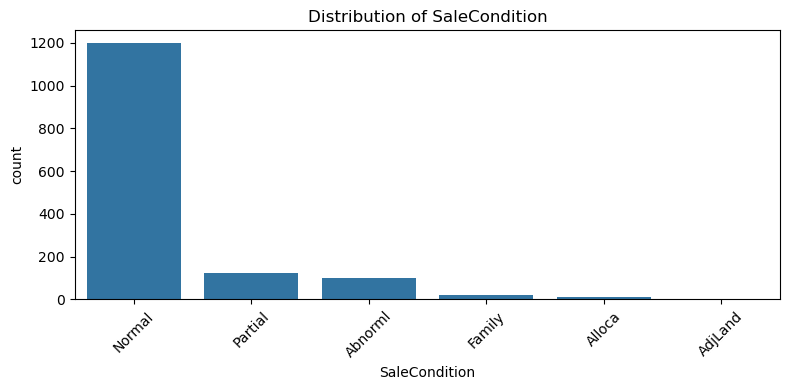

In [4]:
plot_all_columns(df)

<Axes: >

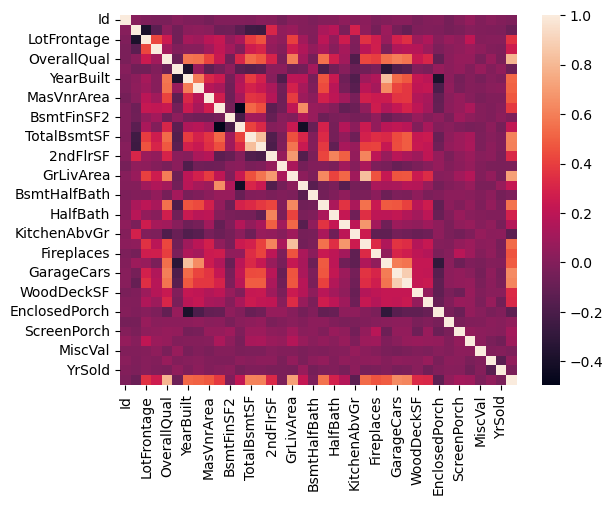

In [5]:
sns.heatmap(df.corr(numeric_only=True))

# Data knowledge and cleannig

In [6]:
print("info",df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
df.drop("Id",axis=1).describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:
df['MSZoning'].value_counts()


MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

# CHECK & Handle Nulls

In [9]:
check=df.isnull().sum()
null_df=[]
for i in check[check>0].index:
     null_df.append((i, check[i], f"{check[i]/len(df)*100:.2f}%"))
pd.DataFrame(null_df, columns=['Column', 'Missing Values', 'Percentage'])

,Column,Missing Values,Percentage
0,LotFrontage,259,17.74%
1,Alley,1369,93.77%
2,MasVnrType,872,59.73%
3,MasVnrArea,8,0.55%
4,BsmtQual,37,2.53%
5,BsmtCond,37,2.53%
6,BsmtExposure,38,2.60%
7,BsmtFinType1,37,2.53%
8,BsmtFinType2,38,2.60%
9,Electrical,1,0.07%


In [10]:
# nulls in LotFrontage	تعني ان واجهة البيت امام الشارع مش معروفه فهنعوض عنها  بمتوسط 
#                        LotFrontage لكل حي Neighborhood
df['LotFrontage']=df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.mean()))


In [11]:
# 	نوع الممر الخلفي  الذي يصل إلى العقار(Alley)
#nulls in Alley مفيش ممر خلفي عوض ب none
df['Alley']=df['Alley'].fillna('None')

In [12]:
#MasVnrType	نوع الـ Masonry Veneer، وهي طبقة تغطية أو كسوة بنائية خارجية.
#nulls in MasVnrType  مفيش نوع من الحجارة عوض ب none
df["MasVnrType"]=df["MasVnrType"].fillna("None")

In [13]:
#MasVnrArea	 مساحة المساحة الـ Masonry Veneer بالقدم المربع.
#nulls in MasVnrArea  البيت مفيهوش Masonry Veneer، فالمساحة الصحيحة هي 0
df["MasVnrArea"]=df["MasVnrArea"].fillna(0)

In [14]:
#BsmtQual	ارتفاع البدروم (Basement Height Quality).
#nulls in BsmtQual  البيت مفيهوش بدروم عوض ب none
df["BsmtQual"]=df["BsmtQual"].fillna("None")
#BsmtCond  الحالة العامة للبدروم.
#nulls in BsmtCond  البيت مفيهوش بدروم عوض ب none
df["BsmtCond"]=df["BsmtCond"].fillna("None")
#BsmtExposure	 مدى تعرض جدران البدروم للضوء أو الخارج 
# BsmtFinType1	نوع تشطيب الجزء الثاني من مساحة البدروم، إذا وُجد أكثر من نوع.
# 	BsmtFinType2 نوع تشطيب الجزء الثاني من مساحة البدروم، إذا وُجد أكثر من نوع.
# هنعوض عنهم كلهم (None) لانهم بيتعلقوا بالبدروم والبيوت اللي مفيهاش بدروم مفيهاش تشطيب للبدروم
df["BsmtExposure"]=df["BsmtExposure"].fillna("None")
df["BsmtFinType1"]=df["BsmtFinType1"].fillna("None")
df["BsmtFinType2"]=df["BsmtFinType2"].fillna("None")

In [15]:
#Electrical نوع النظام الكهربائي
# 1 missing value, هنعوض عنه بالـ mode لان معظم البيوت عندها نظام كهربائي واحد
display(df["Electrical"].value_counts())
# لاقينا ان اصلا المعظم ب SBrkr    1334 من 1459
# ف هنعوض ب ال mode (SBrkr)
df["Electrical"]=df["Electrical"].fillna(df["Electrical"].mode()[0])

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
Name: count, dtype: int64

In [16]:
#FireplaceQu	نوع وجود مدفأة في البيت
#nulls in FireplaceQu  البيت مفيهوش مدفأة عوض ب none
df["FireplaceQu"]=df["FireplaceQu"].fillna("None")

In [17]:
##GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond	
##برضه ال nulls تعني ان مفيش جراج ف هنعوض ب none 
df["GarageType"]=df["GarageType"].fillna("None")
df["GarageYrBlt"]=df["GarageYrBlt"].fillna(0)   
df["GarageFinish"]=df["GarageFinish"].fillna("None")
df["GarageQual"]=df["GarageQual"].fillna("None")
df["GarageCond"]=df["GarageCond"].fillna("None")

In [18]:
#nulls in  PoolQC	 هنعوض ب none لان معظم البيوت مفيهاش حمام سباحة
df["PoolQC"]=df["PoolQC"].fillna("None")
#null in Fence	 هنعوض ب none لان معظم البيوت مفيهاش سور
df["Fence"]=df["Fence"].fillna("None")
#nulls in MiscFeature	 هنعوض ب none لان معظم البيوت مفيهاش ميزه اضافيه
df["MiscFeature"]=df["MiscFeature"].fillna("None")

In [19]:
if sum(df.isnull().sum())>0:
    print("There are still missing values in the dataset.")
else:
    print("All missing values have been handled.")


All missing values have been handled.


In [20]:
df.duplicated().sum()

np.int64(0)

# preprocessin & split data


In [21]:
x=df.drop(['Id','SalePrice'], axis=1)
y=df['SalePrice']

In [22]:
cat=x.select_dtypes(include=['object']).columns.tolist()
num=x.select_dtypes(exclude=['object']).columns.tolist()
print(cat)
print(num)



['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'Enclos

In [209]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [210]:

en=OneHotEncoder(handle_unknown='ignore')
scaler=StandardScaler()
preprocessor=ColumnTransformer(
    transformers=[('num', scaler, num),
                  ('cat', en, cat)]
)

In [211]:
lr=LinearRegression()
model=Pipeline(steps=[('preprocessor', preprocessor),
                      ('regressor', lr)])

In [212]:
model



,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [213]:
model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [214]:
y_pred=model.predict(x_test)
y_train_pred=model.predict(x_train)

In [215]:
print("==================================================")
print("======================Train========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_train, y_train_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_train, y_train_pred))
print("R-squared (R2):", r2_score(y_train, y_train_pred))
print("==================================================")
print("======================Test========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("R-squared (R2):", r2_score(y_test, y_pred))

======================Train========================
Mean Squared Error (MSE): 357567880.6465379
Root Mean Squared Error (RMSE): 18909.465371779763
Mean Absolute Error (MAE): 12131.619691226915
R-squared (R2): 0.9400511592861596
======================Test========================
Mean Squared Error (MSE): 4266583641.471722
Root Mean Squared Error (RMSE): 65319.0909418657
Mean Absolute Error (MAE): 21103.405476777472
R-squared (R2): 0.44375460362117103


كده under fiiting 

# OPtimization


In [216]:
en=OneHotEncoder(handle_unknown='ignore')
scaler=StandardScaler()
preprocessor=ColumnTransformer(
    transformers=[('num', scaler, num),
                  ('cat', en, cat)]
)
model = Pipeline([('preprocessor', preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
     # ("lasso", Lasso(alpha=0.1, max_iter=10000))
])


model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print("R-squared (R2):", r2_score(y_test, y_pred))

R-squared (R2): 0.8715217265749954


In [217]:
print("==================================================")
print("======================Train========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_train, y_train_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_train, y_train_pred))
print("R-squared (R2):", r2_score(y_train, y_train_pred))
print("==================================================")
print("======================Test========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("R-squared (R2):", r2_score(y_test, y_pred))

======================Train========================
Mean Squared Error (MSE): 357567880.6465379
Root Mean Squared Error (RMSE): 18909.465371779763
Mean Absolute Error (MAE): 12131.619691226915
R-squared (R2): 0.9400511592861596
======================Test========================
Mean Squared Error (MSE): 985470267.7059661
Root Mean Squared Error (RMSE): 31392.200746458762
Mean Absolute Error (MAE): 20766.947036764326
R-squared (R2): 0.8715217265749954


In [218]:
en=OneHotEncoder(handle_unknown='ignore')
scaler=StandardScaler()
preprocessor=ColumnTransformer(
    transformers=[('num', scaler, num),
                  ('cat', en, cat)]
)
lasso_params = {"alpha": [0.001, 0.01, 0.1, 1, 10, 100],"max_iter": [5000, 10000]}
grid_lasso=GridSearchCV(Lasso(),lasso_params,cv=5)
#modella = Lasso(alpha=100, max_iter=10000)
model=Pipeline(steps=[('preprocessor', preprocessor),
                      ('regressor', grid_lasso)])

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

c:\Users\youss\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.688e+11, tolerance: 5.374e+08
  model = cd_fast.sparse_enet_coordinate_descent(
c:\Users\youss\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271e+11, tolerance: 5.720e+08
  model = cd_fast.sparse_enet_coordinate_descent(
c:\Users\youss\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.479

In [219]:

print("Best Parameters:")
print(model.named_steps["regressor"].best_params_)

print("Best CV Score:")
print(model.named_steps["regressor"].best_score_)

Best Parameters:
{'alpha': 100, 'max_iter': 5000}
Best CV Score:
0.8107498348859303


In [220]:
print("==================================================")
print("======================Train========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_train, y_train_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_train, y_train_pred))
print("R-squared (R2):", r2_score(y_train, y_train_pred))
print("==================================================")
print("======================Test========================")
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("R-squared (R2):", r2_score(y_test, y_pred))

======================Train========================
Mean Squared Error (MSE): 357567880.6465379
Root Mean Squared Error (RMSE): 18909.465371779763
Mean Absolute Error (MAE): 12131.619691226915
R-squared (R2): 0.9400511592861596
======================Test========================
Mean Squared Error (MSE): 797194338.1158139
Root Mean Squared Error (RMSE): 28234.630121816965
Mean Absolute Error (MAE): 17032.055352762654
R-squared (R2): 0.8960677399392949


# Save model

In [222]:
import joblib
joblib.dump(model,'model.joblib')

['model.joblib']

In [223]:
print("Target minimum:", y.min())
print("Target maximum:", y.max())
print("Target mean:", y.mean())

print("Best parameters:")
print(model.named_steps["regressor"].best_params_)

print("Sample predictions:")
print(model.predict(x_test.iloc[:10]))

Target minimum: 34900
Target maximum: 755000
Target mean: 180921.19589041095
Best parameters:
{'alpha': 100, 'max_iter': 5000}
Sample predictions:
[154866.45572601 347603.42502574  99924.80378764 170694.90936638
 331515.76055074  69480.40034081 234476.97343372 142662.41528133
  65087.16395035 148201.70982983]


In [224]:
# Test a real row from the test set
sample = x_test.iloc[[0]].copy()

sample_prediction = model.predict(sample)[0]

print("Prediction for a real test row:", sample_prediction)
print("Actual price:", y_test.iloc[0])

Prediction for a real test row: 154866.45572600552
Actual price: 154500


In [225]:
saved_model=joblib.load("model.joblib")

In [226]:
sample = x_test.iloc[[0]].copy()
sample_prediction = saved_model.predict(sample)[0]
print("Prediction for a real test row:", sample_prediction)
print("Actual price:", y_test.iloc[0])

Prediction for a real test row: 154866.45572600552
Actual price: 154500
